In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_csv('netflix_customer_churn.csv')

In [13]:
df.sample()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4025,5d21578a-b614-4939-9ce3-0c2e84aed9a4,68,Female,Premium,1.85,3,Europe,Tablet,17.99,0,Gift Card,5,0.46,Romance


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), object(7)
memor

In [14]:
df.columns

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='object')

In [22]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [27]:
df['watch_hours'].skew()

np.float64(2.2591953419514588)

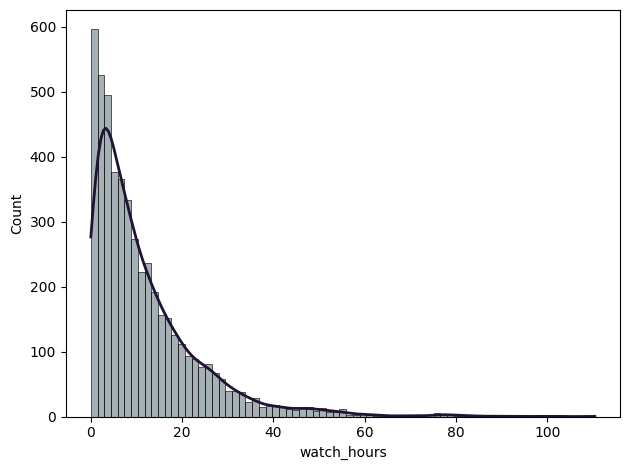

In [24]:
# Right Skewed Data
ax = sns.histplot(
    data=df,
    x="watch_hours",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)

# Box Plot

<Axes: xlabel='watch_hours'>

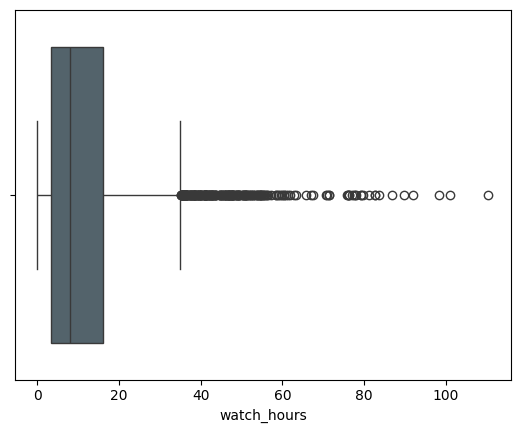

In [25]:
sns.boxplot(data=df,
    x="watch_hours",
    color="#4f646f")

# Finding OutLiers

In [26]:
df['watch_hours'].describe()

count    5000.000000
mean       11.649450
std        12.014654
min         0.010000
25%         3.337500
50%         8.000000
75%        16.030000
max       110.400000
Name: watch_hours, dtype: float64

In [28]:
q1 = df['watch_hours'].quantile(0.25)
q1

np.float64(3.3375)

In [29]:
q3 = df['watch_hours'].quantile(0.75)
q3

np.float64(16.03)

In [30]:
IQR = q3 - q1
IQR

np.float64(12.6925)

In [32]:
min_boxPlot = q1-(1.5*IQR)
min_boxPlot

np.float64(-15.70125)

In [33]:
max_boxPlot = q3 + (1.5* IQR)
max_boxPlot

np.float64(35.06875)

# Trimming

In [39]:
df[(df['watch_hours'] > max_boxPlot) | (df['watch_hours'] < min_boxPlot)].count()

customer_id               238
age                       238
gender                    238
subscription_type         238
watch_hours               238
last_login_days           238
region                    238
device                    238
monthly_fee               238
churned                   238
payment_method            238
number_of_profiles        238
avg_watch_time_per_day    238
favorite_genre            238
dtype: int64

In [41]:
5000 - 238

4762

In [43]:
new_df = df[(df['watch_hours'] < max_boxPlot) & (df['watch_hours'] > min_boxPlot)]
new_df.sample()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
856,1f9510bb-4838-49ae-83dd-4331a0f59f22,66,Other,Standard,29.93,46,Africa,Mobile,13.99,0,Credit Card,5,0.64,Sci-Fi


In [45]:
new_df['customer_id'].info()

<class 'pandas.core.series.Series'>
Index: 4762 entries, 0 to 4999
Series name: customer_id
Non-Null Count  Dtype 
--------------  ----- 
4762 non-null   object
dtypes: object(1)
memory usage: 74.4+ KB


<Axes: xlabel='watch_hours'>

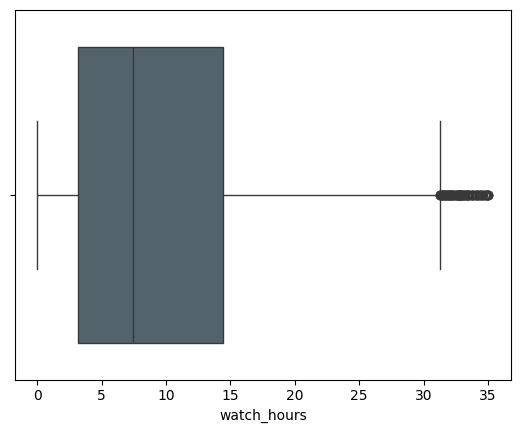

In [47]:
sns.boxplot(data=new_df,
    x="watch_hours",
    color="#4f646f")

In [48]:
new_df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,4762.000000,4762.000000,4762.000000,4762.000000,4762.000000,4762.000000,4762.000000
mean,43.791054,9.772098,30.074549,13.687816,0.527719,3.013020,0.754910
std,15.478743,8.245592,17.547658,3.696197,0.499283,1.417714,2.004576
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.150000,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,7.460000,30.000000,13.990000,1.000000,3.000000,0.270000
75%,57.000000,14.390000,45.000000,17.990000,1.000000,4.000000,0.630000
max,70.000000,35.030000,60.000000,17.990000,1.000000,5.000000,34.530000


# Capping 

In [50]:
df['new_watch_hours'] = np.where((df['watch_hours'] < min_boxPlot), min_boxPlot, np.where((df['watch_hours'] > max_boxPlot),max_boxPlot,df['watch_hours']))
df.sample()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,new_watch_hours
1134,376b1e05-d9f2-4a64-a5f9-7817933d9c19,18,Other,Premium,7.93,60,Oceania,Mobile,17.99,0,Debit Card,4,0.13,Documentary,7.93


<Axes: xlabel='new_watch_hours'>

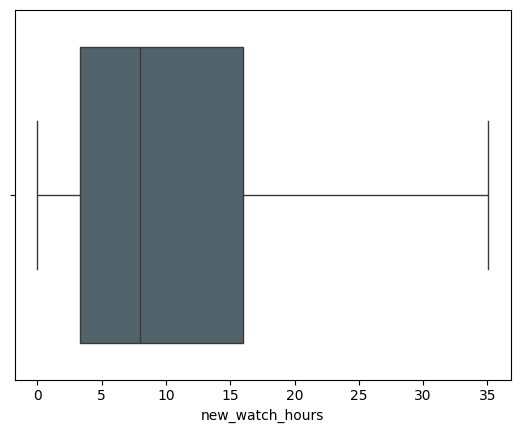

In [51]:
sns.boxplot(data=df,
    x="new_watch_hours",
    color="#4f646f")

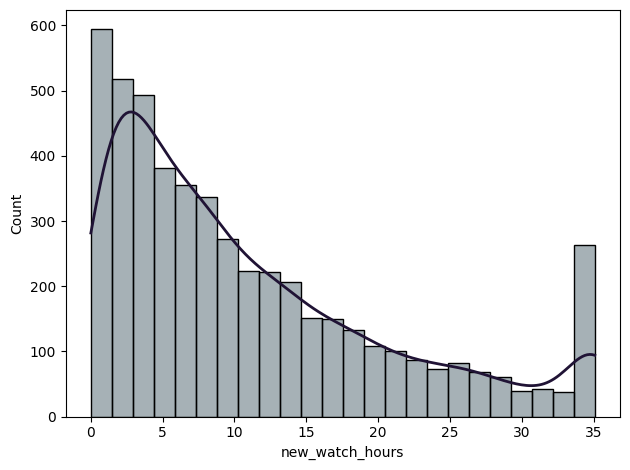

In [52]:
# Right Skewed Data
ax = sns.histplot(
    data=df,
    x="new_watch_hours",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)